# B1.2 et B1.3 — Le catalogue de structures et le filtre par masse

**B1.2** : construire le catalogue (`catalog.parquet`), une ligne par molécule (`inchikey14`), avec la formule et la masse exacte calculées par RDKit **depuis le SMILES**.

**B1.3** : choisir la tolérance du filtre par masse `get_candidates(neutral_mass, ppm)`. C'est un compromis :
- une tolérance trop serrée exclut la vraie molécule à cause de l'erreur de mesure, et rien ne pourra la rattraper ;
- une tolérance trop large donne des milliers de candidats, et le classement devient plus difficile.

On mesure donc, sur les spectres de validation et pour plusieurs tolérances, le **rappel du filtre** (la vraie molécule est-elle parmi les candidats ?) et le **nombre de candidats**.

Le catalogue est trié par masse croissante, donc les candidats d'une fenêtre de masse forment un intervalle de `cat_idx`, trouvé par `np.searchsorted`.

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq

# Racine du dépôt : premier dossier parent qui contient pyproject.toml
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT / "src"))

from casmi.catalog import CATALOG_PATH, N_JOBS, RAW_DIR, build_catalog, mass_windows, smiles_properties
from casmi.mass import compute_neutral_masses

TRAIN_PATH = RAW_DIR / "train.parquet"

pd.set_option("display.max_rows", 100)
print("Données :", TRAIN_PATH)
print("Catalogue :", CATALOG_PATH)
print("Processus pour RDKit :", N_JOBS)

Données : C:\Users\fanny\casmi_data\train.parquet
Catalogue : C:\Users\fanny\casmi_data\processed\catalog.parquet
Processus pour RDKit : 12


## 1. Construction du catalogue (B1.2)

Pour chaque `inchikey14`, on garde le SMILES le plus fréquent parmi ses spectres (à égalité, le premier dans l'ordre alphabétique, pour que le choix soit reproductible). Le catalogue de validation est un « monde fermé » : il contient toutes les molécules du train, y compris celles de la validation.

In [2]:
t0 = time.perf_counter()
catalog = build_catalog()
print(f"{len(catalog):,} molécules, construit en {time.perf_counter() - t0:.0f} s sur {N_JOBS} processus")
print(f"Masses de {catalog['exact_mass'].min():.2f} à {catalog['exact_mass'].max():.2f} Da")
catalog.head()

275,810 molécules, construit en 11 s sur 12 processus
Masses de 31.04 à 3399.57 Da


,cat_idx,inchikey14,smiles,formula,exact_mass
0,0,BAVYZALUXZFZLV,CN,CH5N,31.042199
1,1,OKKJLVBELUTLKV,CO,CH4O,32.026215
2,2,AVXURJPOCDRRFD,NO,H3NO,33.021464
3,3,XLJMAIOERFSOGZ,N#CO,CHNO,43.005814
4,4,IKHGUXGNUITLKF,CC=O,C2H4O,44.026215


### Les molécules qui ont plusieurs SMILES

Un même `inchikey14` peut apparaître avec plusieurs SMILES (stéréoisomères, écritures différentes). Si ces SMILES ont la même formule, le choix n'a aucun effet sur la masse. S'ils ont des formules différentes (forme chargée et forme neutre, par exemple), la masse du catalogue ne conviendra pas à tous les spectres de la molécule.

In [3]:
spectra = pq.read_table(
    TRAIN_PATH,
    columns=["inchikey14", "normalized_smiles", "ingest_lib", "adduct", "precursor_mz"],
    read_dictionary=["ingest_lib", "adduct"],
).to_pandas()

pairs = spectra[["inchikey14", "normalized_smiles"]].drop_duplicates()
smiles_per_key = pairs.groupby("inchikey14").size()
multi = pairs[pairs["inchikey14"].isin(smiles_per_key.index[smiles_per_key > 1])]

props = smiles_properties(multi["normalized_smiles"].unique())
multi = multi.assign(
    formula=multi["normalized_smiles"].map(props["formula"]),
    exact_mass=multi["normalized_smiles"].map(props["exact_mass"]),
)
spread = multi.groupby("inchikey14").agg(
    n_smiles=("normalized_smiles", "size"),
    n_formules=("formula", "nunique"),
    ecart_masse_da=("exact_mass", lambda m: m.max() - m.min()),
)

print(f"Molécules avec plusieurs SMILES : {len(spread):,} ({len(spread) / len(smiles_per_key):.1%})")
print(f"  dont avec des formules différentes : {(spread['n_formules'] > 1).sum():,}")
spread[spread["n_formules"] > 1].sort_values("ecart_masse_da", ascending=False).head(10)

Molécules avec plusieurs SMILES : 1,612 (0.6%)
  dont avec des formules différentes : 118


,n_smiles,n_formules,ecart_masse_da
inchikey14,,,
CTRXDTYTAAKVSM,3,2,1.007276
BXEZTCOKOLHMKY,2,2,1.007276
JSYDBTWJIIAZPU,2,2,1.007276
JFJZZMVDLULRGK,2,2,1.007276
JOUIQRNQJGXQDC,2,2,1.007276
JKHRCGUTYDNCLE,2,2,1.007276
JTPUMZTWMWIVPA,2,2,1.007276
LNFCWEXGZIEGJW,2,2,1.007276
MUJMYVFVAWFUJL,2,2,1.007276


### Les isomères : la limite de la masse

Des molécules de même formule brute ont exactement la même masse. La masse ne pourra **jamais** les départager : c'est le spectre qui devra le faire.

In [4]:
isomers = catalog.groupby("formula").size()
shared = catalog["formula"].map(isomers) > 1

print(f"{len(isomers):,} formules distinctes pour {len(catalog):,} molécules")
print(f"{shared.mean():.1%} des molécules partagent leur formule avec au moins une autre")
isomers.sort_values(ascending=False).head(10).to_frame("n_isomères")

51,232 formules distinctes pour 275,810 molécules
90.6% des molécules partagent leur formule avec au moins une autre


,n_isomères
formula,
C19H24N4O2,477
C18H24N4O2,463
C19H26N4O2,422
C17H22N4O2,409
C18H22N4O2,380
C18H23N3O2,354
C18H23N3O3,350
C19H23N3O3,350
C20H25N3O2,348


## 2. Le jeu de validation (provisoire)

En attendant `split.parquet` de A, on tire 10 % des molécules avec une graine fixe, avec tous leurs spectres, et 2 000 d'entre elles forment le sous-ensemble `dev`. **À remplacer par le split officiel de A** dès qu'il est livré.

In [5]:
keys = np.sort(catalog["inchikey14"].to_numpy())
rng = np.random.default_rng(42)
val_keys = rng.choice(keys, size=int(0.10 * len(keys)), replace=False)
dev_keys = rng.choice(np.sort(val_keys), size=2_000, replace=False)

val = spectra[spectra["inchikey14"].isin(val_keys)].copy()
val["dev"] = val["inchikey14"].isin(dev_keys)
print(f"Validation : {len(val_keys):,} molécules, {len(val):,} spectres "
      f"(dont dev : {val.loc[val['dev'], 'inchikey14'].nunique():,} molécules, {val['dev'].sum():,} spectres)")

Validation : 27,581 molécules, 252,425 spectres (dont dev : 2,000 molécules, 18,945 spectres)


## 3. Rappel du filtre et nombre de candidats selon la tolérance

Pour chaque spectre de validation : masse neutre (`compute_neutral_masses`), fenêtre de candidats, et présence ou non de la vraie molécule dans la fenêtre. Un spectre sans masse neutre (adduct non interprétable) n'a aucun candidat : il compte comme un échec.

In [6]:
masses = catalog["exact_mass"].to_numpy()
key_to_idx = pd.Series(catalog["cat_idx"].to_numpy(), index=catalog["inchikey14"].to_numpy())

val["neutral_mass"] = compute_neutral_masses(val)
val["true_idx"] = val["inchikey14"].map(key_to_idx).to_numpy()

TOLERANCES = [1, 2, 3, 5, 10, 15, 20, 30, 50, 100]


def found_in_window(neutral_masses, true_idx, ppm):
    lo, hi = mass_windows(neutral_masses, masses, ppm)
    return (lo <= true_idx) & (true_idx < hi), hi - lo


def filter_stats(neutral_masses, true_idx, tolerances=TOLERANCES):
    rows = []
    for ppm in tolerances:
        found, n = found_in_window(neutral_masses, true_idx, ppm)
        rows.append({
            "ppm": ppm,
            "rappel (%)": 100 * found.mean(),
            "candidats (médiane)": np.median(n),
            "candidats (90e centile)": np.percentile(n, 90),
            "candidats (max)": n.max(),
        })
    return pd.DataFrame(rows).set_index("ppm").round(1)


per_spectrum = filter_stats(val["neutral_mass"].to_numpy(), val["true_idx"].to_numpy())
per_spectrum

,rappel (%),candidats (médiane),candidats (90e centile),candidats (max)
ppm,,,,
1,52.1,2.0,51.0,477
2,70.8,7.0,89.0,480
3,85.4,15.0,123.0,480
5,92.9,25.0,143.0,482
10,95.2,41.0,180.0,501
15,96.6,58.0,221.0,505
20,97.1,72.0,262.0,742
30,97.7,105.0,382.0,815
50,97.8,189.0,649.0,1021


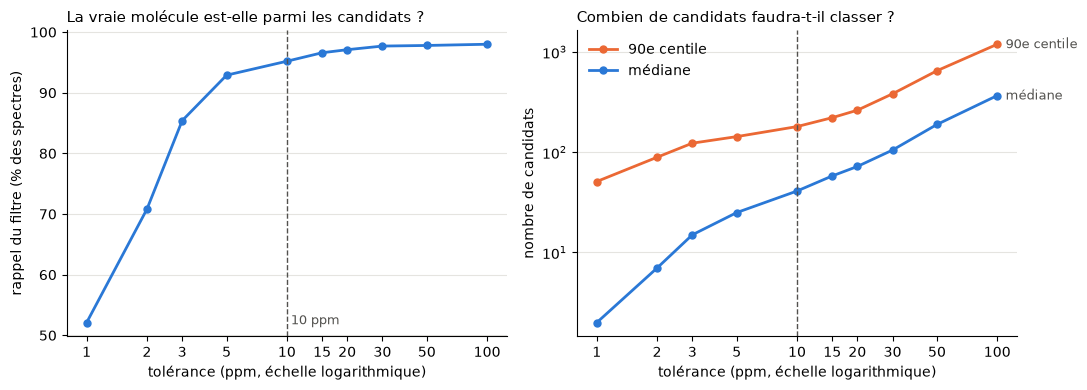

In [7]:
CHOSEN_PPM = 10

fig, (ax_r, ax_n) = plt.subplots(1, 2, figsize=(11, 4), sharex=True)
x = per_spectrum.index.to_numpy()

ax_r.plot(x, per_spectrum["rappel (%)"], color="#2a78d6", linewidth=2, marker="o", markersize=5)
ax_r.set_ylabel("rappel du filtre (% des spectres)")
ax_r.set_title("La vraie molécule est-elle parmi les candidats ?", loc="left", fontsize=11)

for col, color, label in [("candidats (90e centile)", "#eb6834", "90e centile"),
                          ("candidats (médiane)", "#2a78d6", "médiane")]:
    ax_n.plot(x, per_spectrum[col], color=color, linewidth=2, marker="o", markersize=5, label=label)
    ax_n.annotate(label, (x[-1], per_spectrum[col].iloc[-1]), xytext=(6, 0),
                  textcoords="offset points", va="center", color="#52514e", fontsize=9)
ax_n.set_yscale("log")
ax_n.set_ylabel("nombre de candidats")
ax_n.set_title("Combien de candidats faudra-t-il classer ?", loc="left", fontsize=11)
ax_n.legend(frameon=False, loc="upper left")

for ax in (ax_r, ax_n):
    ax.set_xscale("log")
    ax.set_xticks(x, [str(t) for t in x])
    ax.minorticks_off()
    ax.set_xlabel("tolérance (ppm, échelle logarithmique)")
    ax.axvline(CHOSEN_PPM, color="#52514e", linestyle="--", linewidth=1)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#e5e4e0", linewidth=0.8)
    ax.set_axisbelow(True)
ax_r.text(CHOSEN_PPM, 0.04, f" {CHOSEN_PPM} ppm", transform=ax_r.get_xaxis_transform(), color="#52514e", fontsize=9)

fig.tight_layout()
plt.show()

### Rappel par bibliothèque

Les bibliothèques les moins précises en masse (voir le notebook 01) plafonnent plus bas.

In [8]:
true_idx = val["true_idx"].to_numpy()
by_lib = pd.DataFrame({"n_spectres": val.groupby("ingest_lib", observed=True).size()})
for ppm in (5, 10, 20, 50):
    found, _ = found_in_window(val["neutral_mass"].to_numpy(), true_idx, ppm)
    by_lib[f"rappel à {ppm} ppm (%)"] = (
        pd.Series(found, index=val.index).groupby(val["ingest_lib"], observed=True).mean().mul(100).round(1)
    )
by_lib.sort_values("rappel à 10 ppm (%)")

,n_spectres,rappel à 5 ppm (%),rappel à 10 ppm (%),rappel à 20 ppm (%),rappel à 50 ppm (%)
ingest_lib,,,,,
riken,33353,59.5,73.9,87.2,92.0
massbank,9826,87.7,89.1,90.2,90.7
gnps,22083,90.9,92.6,93.4,93.8
mona,9278,90.9,92.8,93.4,93.9
drug_plus,257,94.6,94.9,94.9,94.9
msdial,4154,99.4,99.6,99.6,99.6
spectraverse,4795,99.2,99.9,99.9,99.9
pluskal_ms2,53174,99.9,99.9,99.9,99.9
enveda-180,115360,99.9,100.0,100.0,100.0


## 4. Une masse par molécule

Une molécule de validation a souvent plusieurs spectres, donc plusieurs masses neutres un peu différentes. Le plan propose de les combiner en une seule masse, par exemple la **médiane** : c'est à décider avec C, puisque son évaluation se fait par molécule. La médiane protège aussi contre un spectre isolé mal étiqueté.

In [9]:
per_mol = val.groupby("inchikey14").agg(
    neutral_mass=("neutral_mass", "median"),
    true_idx=("true_idx", "first"),
    n_spectres=("neutral_mass", "size"),
)
per_molecule = filter_stats(per_mol["neutral_mass"].to_numpy(), per_mol["true_idx"].to_numpy())

pd.concat({"par spectre": per_spectrum[["rappel (%)", "candidats (médiane)"]],
           "par molécule (médiane des masses)": per_molecule[["rappel (%)", "candidats (médiane)"]]}, axis=1)

par spectre                     par molécule (médiane des masses)  \
     rappel (%) candidats (médiane)                        rappel (%)   
ppm                                                                     
1          52.1                 2.0                              42.2   
2          70.8                 7.0                              69.1   
3          85.4                15.0                              89.8   
5          92.9                25.0                              98.1   
10         95.2                41.0                              98.6   
15         96.6                58.0                              98.9   
20         97.1                72.0                              98.9   
30         97.7               105.0                              99.0   
50         97.8               189.0                              99.1   
100        98.0               367.0                              99.1   

                         
    candidats (médiane)  
ppm                      
1                   1.0  
2                   9.0  
3                  22.0  
5                  35.0  
10                 56.0  
15                 78.0  
20                 96.0  
30                136.0  
50                243.0  
100               451.0

## 5. Combien de candidats sont de vrais isomères ?

Pour chaque molécule de validation, on compte les molécules du catalogue qui ont **exactement la même formule** qu'elle. C'est le nombre minimal de candidats que la masse ne pourra jamais départager, quelle que soit la tolérance.

In [10]:
formulas = catalog["formula"].to_numpy()
true_formula = formulas[per_mol["true_idx"].to_numpy()]
n_isomers = pd.Series(true_formula).map(isomers).to_numpy()

lo, hi = mass_windows(per_mol["neutral_mass"].to_numpy(), masses, CHOSEN_PPM)
share_isomers = np.array([
    np.mean(formulas[a:b] == f) if b > a else np.nan for a, b, f in zip(lo, hi, true_formula)
])

print(f"Isomères exacts par molécule de validation (elle comprise) : médiane {np.median(n_isomers):.0f}, "
      f"90e centile {np.percentile(n_isomers, 90):.0f}, max {n_isomers.max()}")
print(f"Molécules de validation qui ont au moins un isomère dans le catalogue : {(n_isomers > 1).mean():.1%}")
print(f"À {CHOSEN_PPM} ppm, part médiane des candidats qui sont des isomères exacts : {np.nanmedian(share_isomers):.0%}")

Isomères exacts par molécule de validation (elle comprise) : médiane 20, 90e centile 148, max 477
Molécules de validation qui ont au moins un isomère dans le catalogue : 90.2%
À 10 ppm, part médiane des candidats qui sont des isomères exacts : 56%


## 6. Les erreurs énormes

L'étape 4 de B1.3 (repérer les spectres dont l'erreur est énorme et les signaler à A) est faite dans le notebook 01, section 10 : 25 518 spectres (1 %) à plus de 1000 ppm, avec les écarts typiques qui trahissent un adduct mal étiqueté.

## Conclusions

### B1.2 — Le catalogue

- **275 810 molécules**, une par `inchikey14`, construites en 11 s sur 12 cœurs. Aucun SMILES n'est illisible par RDKit, et le fichier pèse 12,7 Mo.
- 1 612 molécules (0,6 %) ont plusieurs SMILES. Pour 118 d'entre elles, les formules diffèrent, d'au plus un proton (1,007 Da) : c'est la même molécule sous forme protonée et sous forme neutre. Les spectres de la forme non retenue risquent de rater la fenêtre de masse, mais l'effet est négligeable.
- **La masse ne suffit pas.** Il y a 51 232 formules pour 275 810 molécules, et 90,6 % des molécules partagent leur formule avec au moins une autre. Une molécule de validation a en médiane **20 isomères exacts** (elle comprise), et jusqu'à 477. Aucune tolérance ne les départagera : c'est le rôle du spectre et du modèle.

### B1.3 — Le filtre par masse

Sur la validation provisoire (27 581 molécules, 252 425 spectres) :

| tolérance | rappel par spectre | rappel par molécule (médiane des masses) | candidats par spectre (médiane / 90e centile) |
|---|---|---|---|
| 5 ppm | 92,9 % | 98,1 % | 25 / 143 |
| **10 ppm** | **95,2 %** | **98,6 %** | **41 / 180** |
| 20 ppm | 97,1 % | 98,9 % | 72 / 262 |
| 50 ppm | 97,8 % | 99,1 % | 189 / 649 |

- **Le rappel plafonne vers 98 %.** Au-delà de 20 ppm, on ne gagne presque plus rien, alors que le nombre de candidats double à chaque palier. Les 2 % restants sont surtout des étiquettes fausses (notebook 01), qu'aucune tolérance raisonnable ne rattrape.
- **Le rappel dépend surtout de la bibliothèque.** riken n'atteint que 73,9 % à 10 ppm (87,2 % à 20 ppm), alors que enveda-180 et pluskal_ms2 sont à environ 100 % dès 5 ppm.
- **Combiner les spectres d'une molécule par la médiane de leurs masses** fait passer le rappel à 10 ppm de 95,2 % à 98,6 %. C'est à proposer à C pour l'évaluation par molécule.
- À 10 ppm, environ la moitié des candidats (56 % en médiane) sont des isomères exacts de la bonne molécule.

**Tolérance proposée : 10 ppm** (à valider en réunion). C'est le coude de la courbe : passer de 5 à 10 ppm gagne 2,3 points de rappel pour 16 candidats de plus en médiane, et passer de 10 à 20 ppm ne gagne que 1,9 point pour 31 candidats de plus. C'est aussi la valeur par défaut prévue pour `get_candidates`. **À tester avec l'évaluation de C** : comparer le MRR à 10 et à 20 ppm, puisque riken gagne beaucoup à 20 ppm et que les bibliothèques précises n'y perdent rien.